In [2]:
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

In [3]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


In [5]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

In [6]:
# 导入数据，并观察数据形状
from keras.datasets import imdb
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=10000)

print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (25000,)
训练集标签形状: (25000,)
测试集特征形状: (25000,)
测试集标签形状: (25000,)


In [7]:
print(x_train[0])
print(y_train[0])

[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]
1


In [8]:
# one-hot编码：针对10000个高频词，将每条评论数据，转换为10000个元素的序列
def vectorize_sequences(sequences, dimension=10000):   
    results = np.zeros((len(sequences), dimension)) # 形状：(len(str_val), 10000)
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

x_train = vectorize_sequences(x_train) 
x_test = vectorize_sequences(x_test)
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

In [9]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32).to(device)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32).to(device)

y_train_tensor = torch.tensor(y_train, dtype = torch.float32).to(device) # 二分类标签，类型必须是torch.float32
y_test_tensor = torch.tensor(y_test, dtype = torch.float32).to(device)

In [10]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10000, 16) # 输入层 10000 -> 隐藏层1 16
        self.fc2 = nn.Linear(16, 16) # 隐藏层1 16 -> 隐藏层2 16
        self.out = nn.Linear(16, 1) # 隐藏层2 16 -> 输出层 1
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 输出线性结果
        return x

In [11]:
model = Net() # 定义模型
criterion = nn.BCEWithLogitsLoss() # 损失函数（二元交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

In [12]:
# 训练模型，并在每轮epoch后，针对训练数据评估模型
def train_model(model, epochs, batch):
    # 将模型迁移到GPU训练
    model = model.to(device)

    # 全数据集分batch
    g = torch.Generator()
    g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子
    
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor) # 特征与标签，一起构造成torch张量数据集
    train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g) # 将数据集组织成 以batch加载 的形式
    
    loss_result = []

    for epoch in range(epochs):
        train_total_loss_sum = 0.0  # 记录每个epoch的总损失
        train_num = 0   # 记录训练集的总样本数

        model.train() # 设置为训练模式
        for batch_x, batch_y in train_dataloader:
            optimizer.zero_grad() # 梯度清零
            preds_y = model(batch_x) # 前向传播
            loss_train = criterion(preds_y, batch_y) # 计算损失
            loss_train.backward() # 反向传播（自动求导 并 累加梯度）
            optimizer.step() # 根据求导计算出的 梯度，更新模型参数

            train_total_loss_sum += loss_train.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            train_num += batch_y.size(0)

        train_correct = 0
        
        model.eval() # 设置为评估模式
        with torch.no_grad(): # 关闭梯度计算，节省内存
            for batch_x, batch_y in train_dataloader:
                # 前向传播
                train_preds = model(batch_x)    
                # 将输出层的线性结果sigmoid化，并以0.5为阈值作0-1分类             
                predicted_classes = (torch.sigmoid(train_preds) > 0.5).float()  
                # 统计预测正确的样本数
                train_correct += (predicted_classes == batch_y).sum().item() 
        
        loss_result.append([f"{epoch + 1}/{epochs}", train_total_loss_sum / train_num, train_correct / train_num]) # 记录每epoch的loss与Acc
        # print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {train_total_loss_sum / train_num:.4f}, 训练集Acc: {train_correct / train_num * 100:.2f}%  ({train_correct}/{train_num})")

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Loss', 'Acc'])
    return result_df

In [13]:
train_result_df = train_model(model, epochs=20, batch = 512)
train_result_df.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/20,0.447537,91.73%
2/20,0.238321,94.26%
3/20,0.183040,95.31%
4/20,0.153422,95.89%
5/20,0.133575,96.66%
6/20,0.115579,97.48%
7/20,0.098080,97.95%
8/20,0.083717,98.62%
9/20,0.069986,96.91%
10/20,0.061939,99.23%


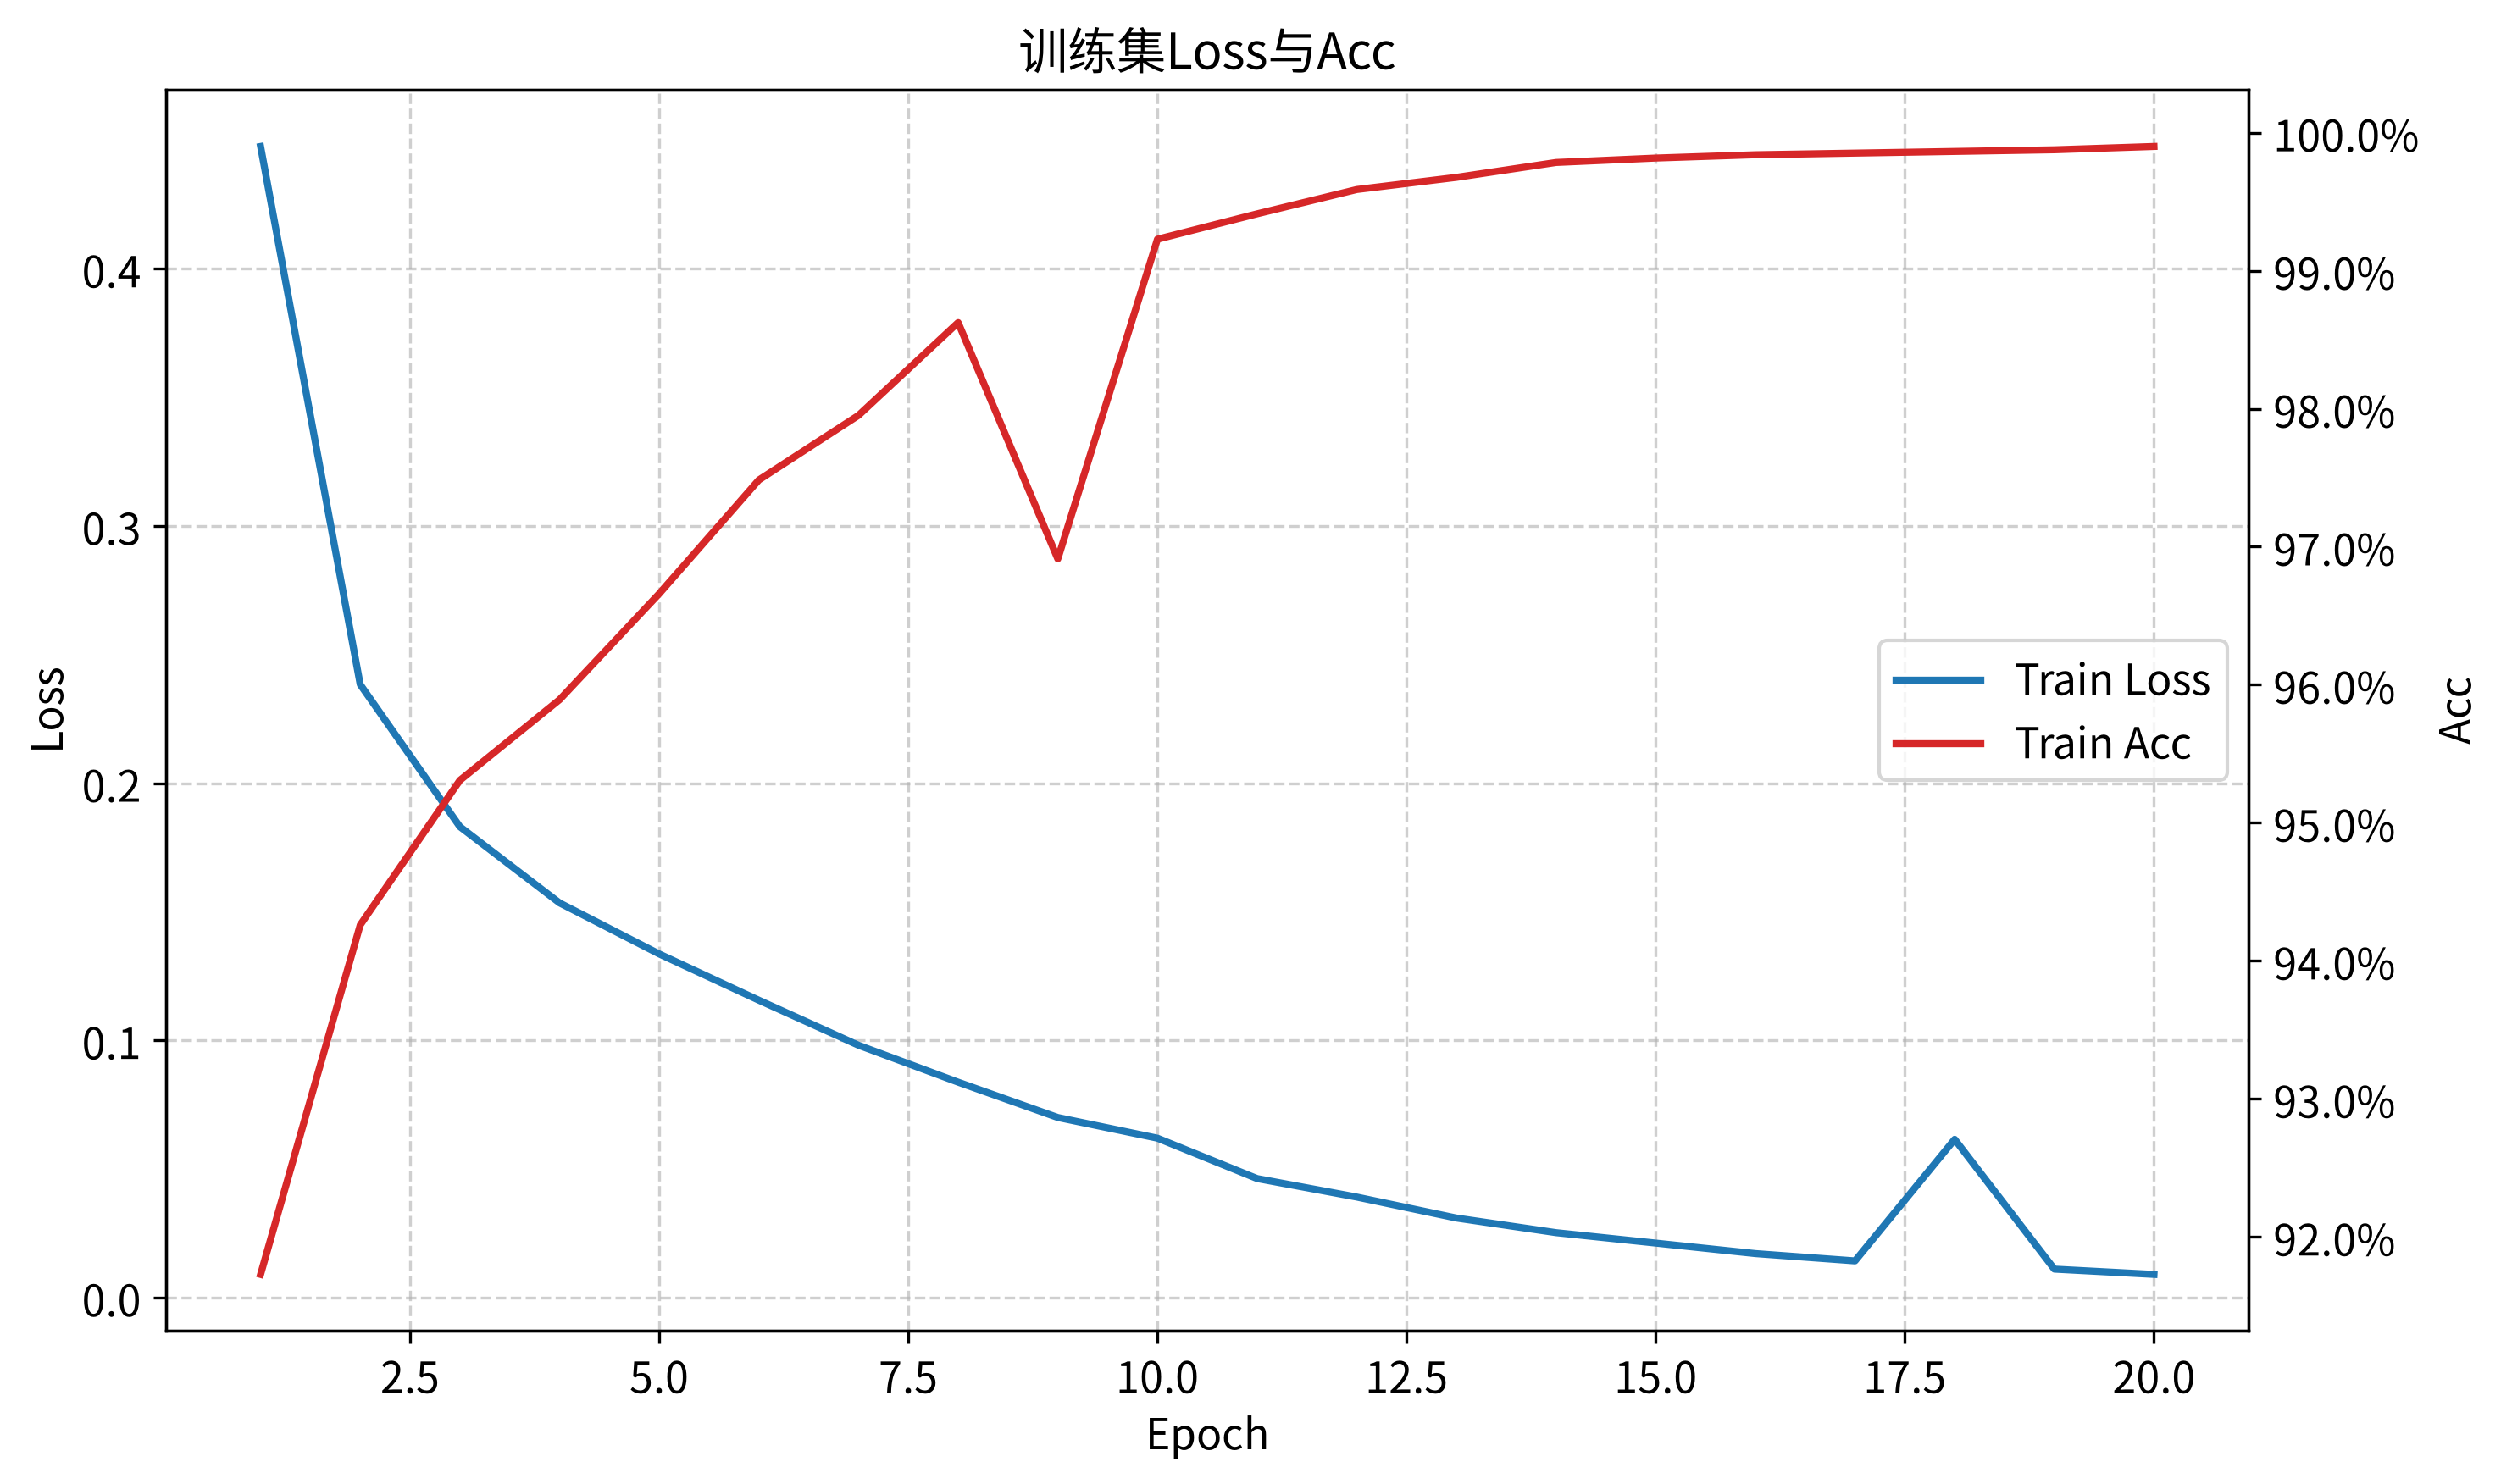

In [14]:
# 从结果列表中提取 loss 和 acc 数据
losses = train_result_df['Loss']
accs = train_result_df['Acc']
epochs = range(1, len(losses) + 1)

# 初始化画布
fig, ax1 = plt.subplots(figsize=(10, 6)) # ax1 作为左侧主坐标轴

# 绘制左侧Loss（蓝线）
color_loss = 'tab:blue'
line1 = ax1.plot(epochs, losses, label='Train Loss', color=color_loss, linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.tick_params(axis='y') # 刻度线颜色与线条一致
ax1.grid(True, linestyle='--', alpha=0.6) # 加网格

# 绘制右侧Acc（红线）
ax2 = ax1.twinx()  
color_acc = 'tab:red'
line2 = ax2.plot(epochs, accs, label='Train Acc', color=color_acc, linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.tick_params(axis='y')

ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1)) # 将Acc轴格式化为百分比

# 合并图例
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', fontsize=12)

# 设置标题并显示
plt.title('训练集Loss与Acc', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# 在测试集上评估模型并预测
def evaluate_model(model, batch):
    model.eval() # 将模型切换到测试状态
    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []
    test_probs = []

    # 同样分batch进行测试
    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad(): # 关闭梯度计算，节省内存
        for batch_x, batch_y in test_dataloader:
            test_preds = model(batch_x) # 前向传播
            loss = criterion(test_preds, batch_y) # 计算单batch的平均loss
            test_total_loss_sum += loss.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            
            probs_positive = torch.sigmoid(test_preds)           # 计算positive的概率
            predicted_classes = (probs_positive > 0.5).float()   # 计算预测结果

            test_result += predicted_classes.view(-1).tolist()   # 追加预测结果
            test_probs += [[num, 1 - num] for num in probs_positive.view(-1).tolist()] # 将正向概率转为[正向概率, 负向概率]列表

            test_correct += (predicted_classes == batch_y).sum().item()  # 计算预测正确的数量
            test_num += len(batch_x)  # 计算总样本数

    avg_test_loss = test_total_loss_sum / test_num  # 计算总平均loss
    accuracy = test_correct / test_num    # 计算Acc

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    # 预测结果
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    # 预测该数字为0-9的原始概率
    prob_columns = ['Positive', 'Negative'] 
    prob_df = pd.DataFrame(test_probs, columns=prob_columns)
    # 合并成一个df
    result_df = pd.concat([result_df, prob_df], axis=1)
    
    return result_df

In [29]:
test_result = evaluate_model(model, batch=128)
test_result.round(4)

测试集loss: 0.7104
测试集Acc: 85.88%  (21471/25000)


,Predict,Positive,Negative
0,0.0,0.0372,0.9628
1,1.0,1.0000,0.0000
2,1.0,0.9841,0.0159
3,1.0,0.9989,0.0011
4,1.0,0.9994,0.0006
...,...,...,...
24995,1.0,1.0000,0.0000
24996,1.0,0.7809,0.2191
24997,0.0,0.0193,0.9807
24998,0.0,0.0087,0.9913
